# Predicting Housing Prices in Buenos Aires

This notebook develops and evaluates price models, with Capital Federal as the primary market.

## 1. Import Libraries

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid")

## 2. Import and Combine Data

Load both listing extracts and preserve their shared schema.

In [2]:
data_dir = Path("data")
paths = sorted(data_dir.glob("buenos-aires-real-estate-*.csv"))

raw = pd.concat((pd.read_csv(path) for path in paths), ignore_index=True)
print(f"Files: {len(paths)}")
print(f"Rows: {len(raw):,}")
print(f"Columns: {raw.shape[1]}")

Files: 2
Rows: 17,212
Columns: 16


In [3]:
raw.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499","180,000.00",USD,"2,729,232.00","180,000.00",120.00,110.00,"1,500.00","1,636.36",NaN,4.00,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,"250,000.00",USD,"3,790,600.00","250,000.00",117.00,120.00,"2,136.75","2,083.33",NaN,4.00,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073","410,000.00",USD,"6,216,584.00","410,000.00",410.00,220.00,"1,000.00","1,863.64",NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503","180,000.00",USD,"2,729,232.00","180,000.00",200.00,135.00,900.00,"1,333.33",NaN,5.00,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614","129,000.00",USD,"1,955,949.60","129,000.00",76.00,70.00,"1,697.37","1,842.86",NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...


## 3. Validate the Raw Data

Check schema consistency, duplicates, operation type, geography, and target availability.

In [4]:
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate listing URLs:", raw["properati_url"].duplicated().sum())
print("Operations:\n", raw["operation"].value_counts(dropna=False))
print("\nMissing target values:", raw["price_aprox_usd"].isna().sum())
print(
    "\nTop regions:\n",
    raw["place_with_parent_names"]
    .dropna()
    .str.strip("|")
    .str.split("|")
    .str[2]
    .value_counts(),
)

Duplicate rows: 0
Duplicate listing URLs: 0
Operations:
 operation
sell    17212
Name: count, dtype: int64

Missing target values: 2011

Top regions:
 place_with_parent_names
Tigre                    1942
La Matanza               1662
Morón                     993
Vicente López             881
San Isidro                804
                         ... 
Distrito de las Artes       5
Cañuelas                    4
Villa Real                  3
Catalinas                   1
Villa Soldati               1
Name: count, Length: 89, dtype: int64


## 4. Clean and Engineer Features

Keep valid sale listings with a positive USD price. Optional listing fields remain available for pipeline imputation.

In [5]:
df = raw.drop_duplicates().copy()

numeric_columns = [
    "price",
    "price_aprox_local_currency",
    "price_aprox_usd",
    "surface_total_in_m2",
    "surface_covered_in_m2",
    "price_usd_per_m2",
    "price_per_m2",
    "floor",
    "rooms",
    "expenses",
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.loc[
    df["operation"].eq("sell")
    & df["price_aprox_usd"].notna()
    & (df["price_aprox_usd"] > 0)
].copy()

for column in ["surface_total_in_m2", "surface_covered_in_m2", "rooms", "expenses"]:
    df.loc[df[column] <= 0, column] = np.nan
df.loc[df["floor"] <= 0, "floor"] = np.nan

invalid_area = (
    df["surface_total_in_m2"].notna()
    & df["surface_covered_in_m2"].notna()
    & (df["surface_covered_in_m2"] > df["surface_total_in_m2"])
)
df.loc[invalid_area, "surface_covered_in_m2"] = np.nan

parts = df["place_with_parent_names"].fillna("").str.strip("|").str.split("|")
df["province"] = parts.str[0]
df["region"] = parts.str[1]
df["municipality"] = parts.str[2]
df["neighborhood"] = parts.str[3].fillna(parts.str[2])

coordinates = df["lat-lon"].str.split(",", n=1, expand=True)
df["latitude"] = pd.to_numeric(coordinates[0], errors="coerce")
df["longitude"] = pd.to_numeric(coordinates[1], errors="coerce")

df["log_price_usd"] = np.log1p(df["price_aprox_usd"])
print(f"Cleaned rows: {len(df):,}")

Cleaned rows: 15,196


### Missingness profile

Missing values are quantified here and handled later inside model pipelines.

In [6]:
missingness = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_percent")
    .to_frame()
)
missingness.head(15)

,missing_percent
expenses,88.73
floor,83.76
rooms,44.29
surface_total_in_m2,35.86
price_usd_per_m2,35.86
longitude,18.70
lat-lon,18.70
latitude,18.70
surface_covered_in_m2,16.02
price_per_m2,14.11


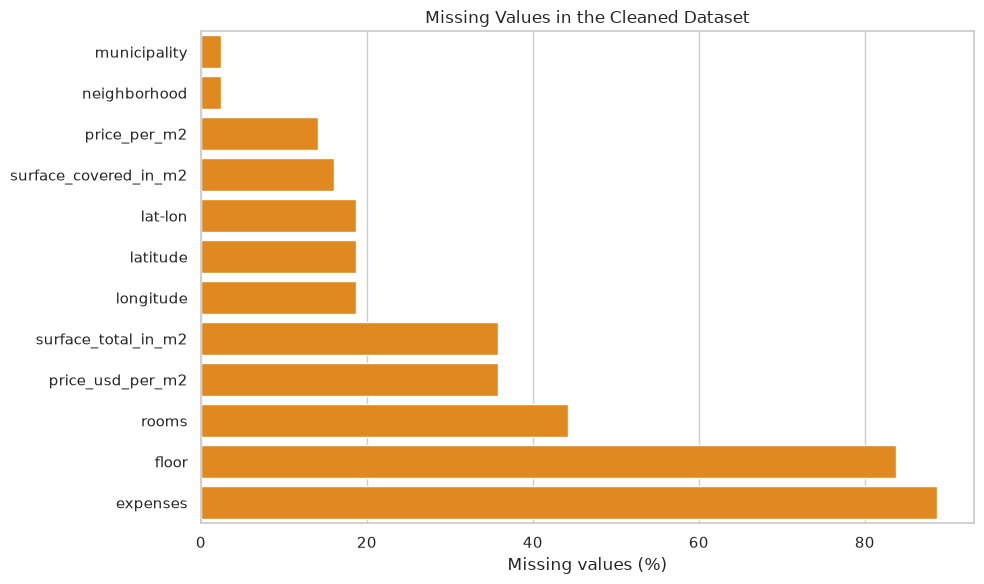

In [7]:
plt.figure(figsize=(10, 6))
plot_missing = missingness.head(12).sort_values("missing_percent")
sns.barplot(
    x="missing_percent", y=plot_missing.index, data=plot_missing, color="darkorange"
)
plt.title("Missing Values in the Cleaned Dataset")
plt.xlabel("Missing values (%)")
plt.ylabel("")
plt.tight_layout()

## 5. Define the Primary Market

Capital Federal is the primary modeling cohort. The wider market remains available for context and out-of-scope robustness checks.

In [8]:
capital = df.loc[df["region"].eq("Capital Federal")].copy()
non_capital = df.loc[~df["region"].eq("Capital Federal")].copy()

print(f"Capital Federal listings: {len(capital):,}")
print(f"Other Buenos Aires listings: {len(non_capital):,}")
print("\nCapital Federal property types:\n", capital["property_type"].value_counts())
print("\nCapital Federal neighborhoods:", capital["neighborhood"].nunique())

Capital Federal listings: 4,638
Other Buenos Aires listings: 10,558

Capital Federal property types:
 property_type
apartment    3857
PH            336
house         283
store         162
Name: count, dtype: int64

Capital Federal neighborhoods: 57


## 6. Exploratory Data Analysis

Use EDA to understand skew, market composition, size relationships, and neighborhood variation before modeling.

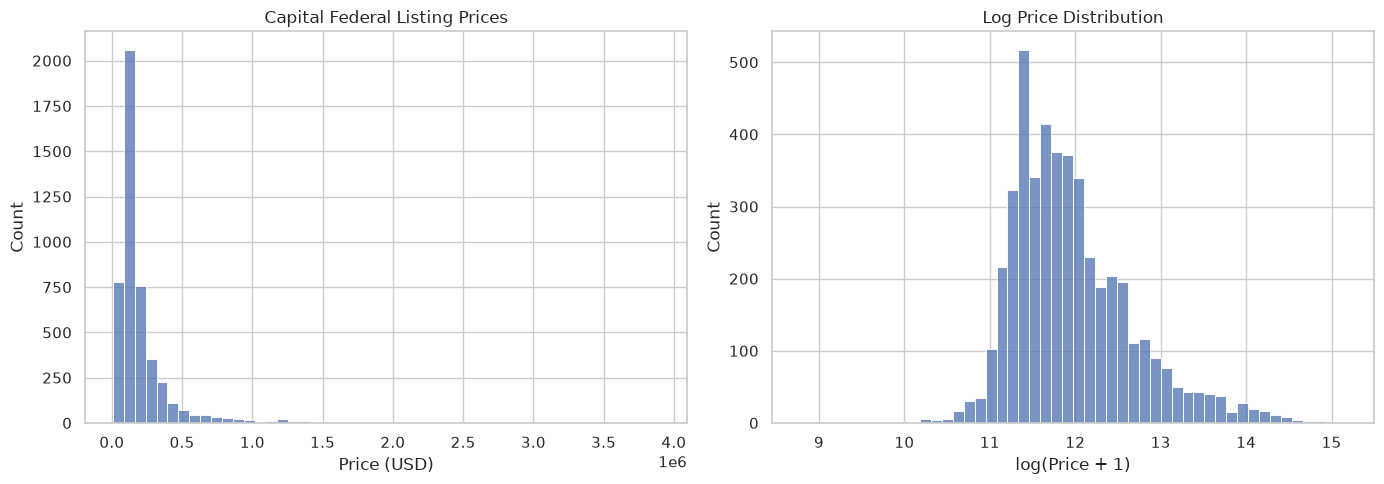

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(capital["price_aprox_usd"], bins=50, ax=axes[0])
axes[0].set_title("Capital Federal Listing Prices")
axes[0].set_xlabel("Price (USD)")
sns.histplot(capital["log_price_usd"], bins=50, ax=axes[1])
axes[1].set_title("Log Price Distribution")
axes[1].set_xlabel("log(Price + 1)")
plt.tight_layout()

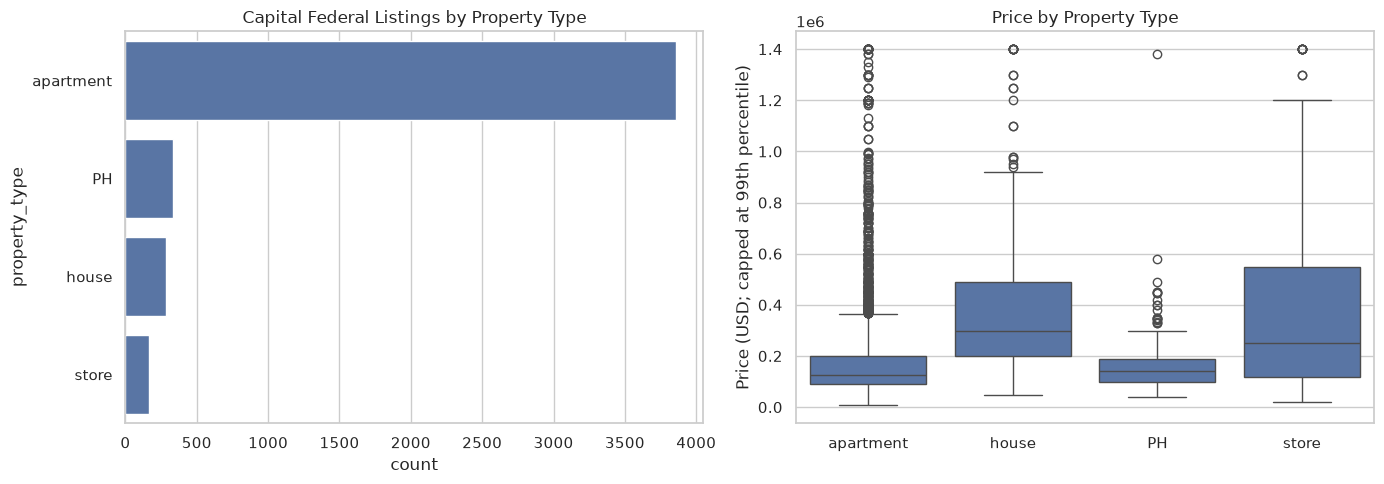

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = capital["property_type"].value_counts().index
sns.countplot(data=capital, y="property_type", order=order, ax=axes[0])
axes[0].set_title("Capital Federal Listings by Property Type")

price_plot = capital.assign(
    capped_price=capital["price_aprox_usd"].clip(
        upper=capital["price_aprox_usd"].quantile(0.99)
    )
)
sns.boxplot(data=price_plot, x="property_type", y="capped_price", ax=axes[1])
axes[1].set_title("Price by Property Type")
axes[1].set_xlabel("")
axes[1].set_ylabel("Price (USD; capped at 99th percentile)")
plt.tight_layout()

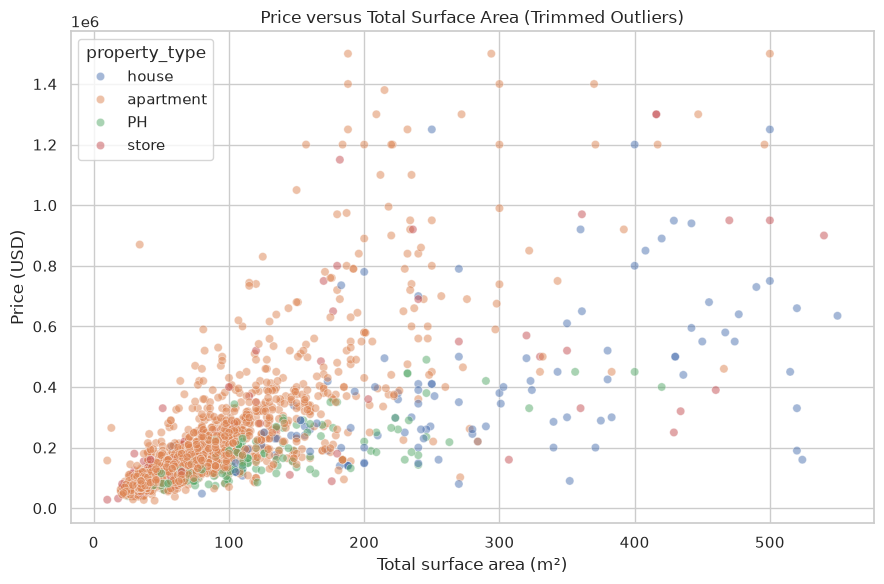

In [23]:
plot_size = capital[
    ["surface_total_in_m2", "price_aprox_usd", "property_type"]
].dropna()

# Remove non-positive values
plot_size = plot_size.loc[plot_size["surface_total_in_m2"] > 0]

# Trim upper 1% outliers on BOTH price and surface area
plot_size = plot_size.loc[
    (plot_size["price_aprox_usd"] <= plot_size["price_aprox_usd"].quantile(0.99))
    & (plot_size["surface_total_in_m2"] <= plot_size["surface_total_in_m2"].quantile(0.99))
]

plot_size = plot_size.sample(min(2500, len(plot_size)), random_state=42)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_size,
    x="surface_total_in_m2",
    y="price_aprox_usd",
    hue="property_type",
    alpha=0.5,
)
plt.title("Price versus Total Surface Area (Trimmed Outliers)")
plt.xlabel("Total surface area (m²)")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()


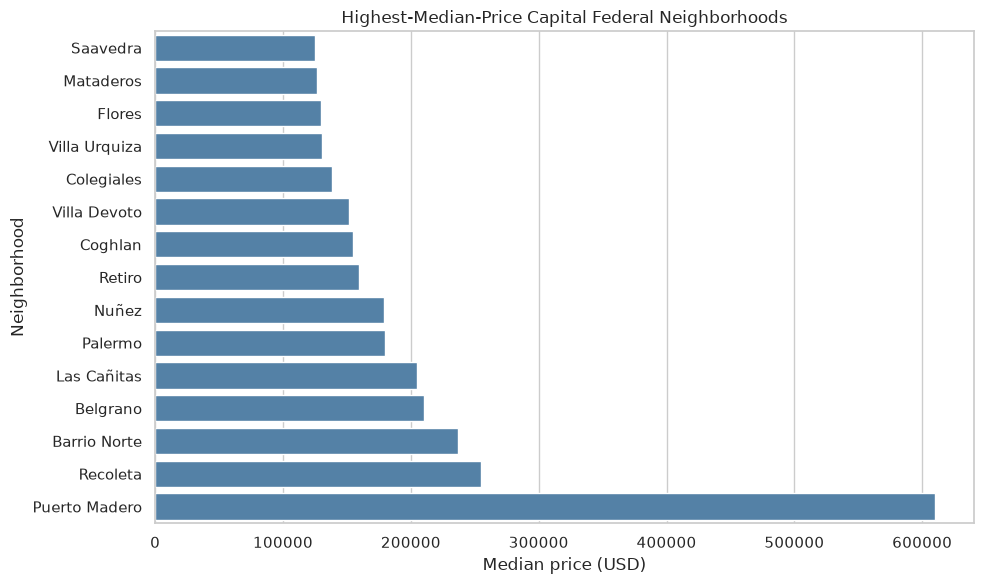

In [24]:
neighborhood_summary = (
    capital.groupby("neighborhood")
    .agg(
        listings=("price_aprox_usd", "size"), median_price=("price_aprox_usd", "median")
    )
    .query("listings >= 20")
    .sort_values("median_price", ascending=False)
    .head(15)
    .sort_values("median_price")
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=neighborhood_summary,
    x="median_price",
    y=neighborhood_summary.index,
    color="steelblue",
)
plt.title("Highest-Median-Price Capital Federal Neighborhoods")
plt.xlabel("Median price (USD)")
plt.ylabel("Neighborhood")
plt.tight_layout()

## 7. Define Modeling Features

Target-derived price-per-square-metre fields and listing URLs are excluded to prevent leakage and identifier memorization.

In [25]:
target = "price_aprox_usd"
leakage_columns = ["price_usd_per_m2", "price_per_m2", "log_price_usd"]
feature_columns = [
    "property_type",
    "neighborhood",
    "municipality",
    "surface_total_in_m2",
    "surface_covered_in_m2",
    "floor",
    "rooms",
    "expenses",
    "latitude",
    "longitude",
]

X = capital[feature_columns].copy()
y = capital[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print("Excluded from predictors:", leakage_columns + ["properati_url"])

Training rows: 3,710
Test rows: 928
Excluded from predictors: ['price_usd_per_m2', 'price_per_m2', 'log_price_usd', 'properati_url']


## 8. Establish Baselines

Compare a global median with a neighborhood/property-type median. These baselines set a practical minimum for model performance.

In [26]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": np.mean(np.abs((actual - predicted) / actual)) * 100,
        "R2": r2_score(actual, predicted),
    }


global_median = y_train.median()
global_pred = np.full(len(y_test), global_median)

train_groups = pd.DataFrame(
    {
        "neighborhood": X_train["neighborhood"],
        "property_type": X_train["property_type"],
        "target": y_train,
    }
)
group_medians = train_groups.groupby(["neighborhood", "property_type"])[
    "target"
].median()


def group_baseline(frame):
    values = []
    for _, row in frame.iterrows():
        key = (row["neighborhood"], row["property_type"])
        values.append(group_medians.get(key, global_median))
    return np.asarray(values)


group_pred = group_baseline(X_test)
baseline_results = pd.DataFrame(
    [
        {
            "model": "Global median",
            "target": "USD",
            **regression_metrics(y_test, global_pred),
        },
        {
            "model": "Neighborhood + type median",
            "target": "USD",
            **regression_metrics(y_test, group_pred),
        },
    ]
)
baseline_results

,model,target,MAE,RMSE,MAPE,R2
0,Global median,USD,"117,277.06","245,583.00",50.76,-0.11
1,Neighborhood + type median,USD,"105,442.94","221,928.53",53.57,0.10


## 9. Build Preprocessing Pipelines

Imputation, scaling, and encoding are fitted only on training data through a shared preprocessing pipeline.

In [27]:
numeric_features = [
    "surface_total_in_m2",
    "surface_covered_in_m2",
    "floor",
    "rooms",
    "expenses",
    "latitude",
    "longitude",
]
categorical_features = ["property_type", "neighborhood", "municipality"]

preprocessor = ColumnTransformer(
    [
        (
            "numeric",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_features,
        ),
        (
            "categorical",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    (
                        "encoder",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            min_frequency=10,
                            sparse_output=False,
                        ),
                    ),
                ]
            ),
            categorical_features,
        ),
    ],
    remainder="drop",
)

## 10. Compare Models and Target Scales

Evaluate ordinary and regularized linear models alongside tree ensembles. Raw-price and log-price targets are compared on the same USD test set.

In [28]:
models = {
    "Linear regression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "Lasso": Lasso(alpha=100.0, max_iter=20_000),
    "Random forest": RandomForestRegressor(
        n_estimators=150, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Gradient boosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42
    ),
}


def fit_and_score(model, target_name):
    target_train = np.log1p(y_train) if target_name == "log-USD" else y_train
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", model)])

    def usd_mae_scorer(estimator, X_valid, y_valid):
        prediction = estimator.predict(X_valid)
        actual = np.expm1(y_valid) if target_name == "log-USD" else y_valid
        if target_name == "log-USD":
            prediction = np.expm1(np.clip(prediction, -20, 20))
        return -mean_absolute_error(actual, prediction)

    cv_scores = cross_val_score(
        pipeline, X_train, target_train, cv=3, scoring=usd_mae_scorer, n_jobs=1
    )
    pipeline.fit(X_train, target_train)
    prediction = pipeline.predict(X_test)
    if target_name == "log-USD":
        prediction = np.expm1(prediction)
    return (
        pipeline,
        regression_metrics(y_test, prediction),
        -cv_scores.mean(),
        prediction,
    )


results = []
fits = {}
for target_name in ["USD", "log-USD"]:
    for model_name, estimator in models.items():
        fitted, metrics, cv_mae, prediction = fit_and_score(estimator, target_name)
        fits[(model_name, target_name)] = (fitted, prediction)
        results.append(
            {
                "model": model_name,
                "target": target_name,
                "CV_USD_MAE": cv_mae,
                **metrics,
            }
        )

model_results = pd.DataFrame(results).sort_values("CV_USD_MAE")
model_results

,model,target,CV_USD_MAE,MAE,RMSE,MAPE,R2
8,Random forest,log-USD,"58,317.47","50,935.65","113,060.60",23.79,0.77
3,Random forest,USD,"61,162.48","49,904.42","100,393.16",25.70,0.82
9,Gradient boosting,log-USD,"61,642.30","56,320.66","126,042.88",26.57,0.71
4,Gradient boosting,USD,"68,249.32","60,532.54","116,265.58",34.27,0.75
7,Lasso,log-USD,"123,524.93","118,924.20","240,026.17",59.61,-0.06
1,Ridge,USD,"125,357.93","99,850.21","172,450.69",62.38,0.45
2,Lasso,USD,"126,685.34","99,806.94","172,894.27",62.07,0.45
0,Linear regression,USD,"127,826.79","100,751.12","173,279.34",62.86,0.45
6,Ridge,log-USD,"220,605.56","87,608.09","234,265.51",38.51,-0.01
5,Linear regression,log-USD,"221,159.36","88,220.94","238,176.46",38.76,-0.04


In [29]:
comparison = pd.concat([baseline_results, model_results], ignore_index=True)
comparison.sort_values("MAE")

,model,target,MAE,RMSE,MAPE,R2,CV_USD_MAE
3,Random forest,USD,"49,904.42","100,393.16",25.70,0.82,"61,162.48"
2,Random forest,log-USD,"50,935.65","113,060.60",23.79,0.77,"58,317.47"
4,Gradient boosting,log-USD,"56,320.66","126,042.88",26.57,0.71,"61,642.30"
5,Gradient boosting,USD,"60,532.54","116,265.58",34.27,0.75,"68,249.32"
10,Ridge,log-USD,"87,608.09","234,265.51",38.51,-0.01,"220,605.56"
11,Linear regression,log-USD,"88,220.94","238,176.46",38.76,-0.04,"221,159.36"
8,Lasso,USD,"99,806.94","172,894.27",62.07,0.45,"126,685.34"
7,Ridge,USD,"99,850.21","172,450.69",62.38,0.45,"125,357.93"
9,Linear regression,USD,"100,751.12","173,279.34",62.86,0.45,"127,826.79"
1,Neighborhood + type median,USD,"105,442.94","221,928.53",53.57,0.10,NaN


## 11. Select and Inspect the Best Model

Select the lowest-MAE model, then inspect errors and performance across property types and price bands.

In [30]:
best_row = model_results.sort_values("CV_USD_MAE").iloc[0]
best_key = (best_row["model"], best_row["target"])
best_pipeline, best_prediction = fits[best_key]

print(f"Selected model: {best_key[0]} ({best_key[1]} target)")
print(f"Test MAE: ${best_row['MAE']:,.0f}")
print(f"Test RMSE: ${best_row['RMSE']:,.0f}")
print(f"Test MAPE: {best_row['MAPE']:.1f}%")
print(f"Test R²: {best_row['R2']:.3f}")

Selected model: Random forest (log-USD target)
Test MAE: $50,936
Test RMSE: $113,061
Test MAPE: 23.8%
Test R²: 0.765


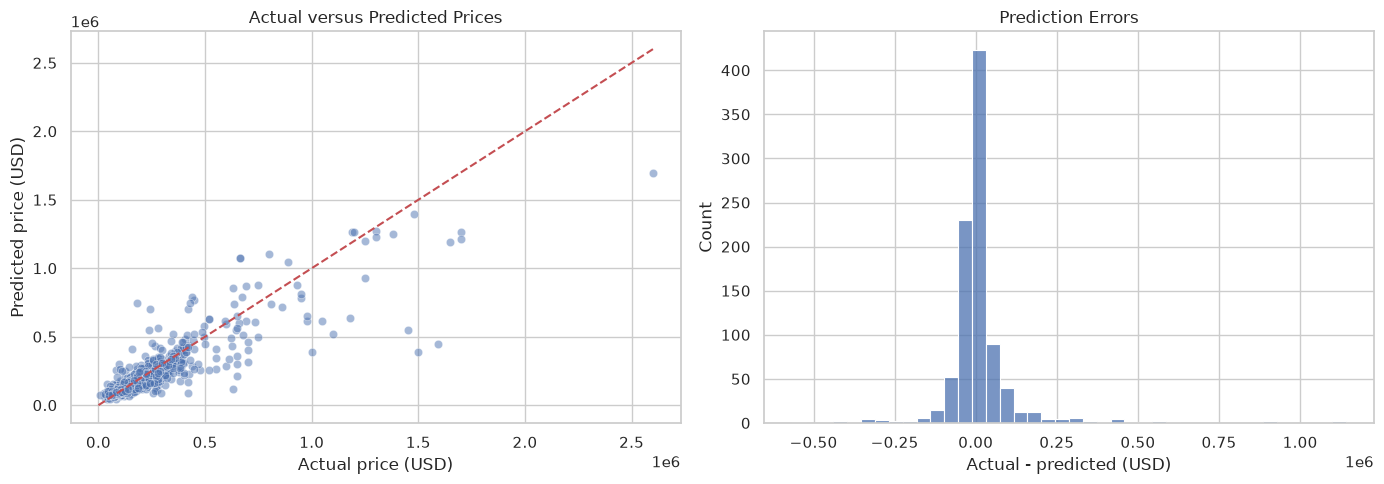

In [31]:
residuals = pd.DataFrame(
    {
        "actual": y_test,
        "predicted": best_prediction,
        "error": y_test.to_numpy() - best_prediction,
        "property_type": X_test["property_type"].to_numpy(),
        "neighborhood": X_test["neighborhood"].to_numpy(),
    }
)
residuals["absolute_error"] = residuals["error"].abs()
residuals["price_band"] = pd.qcut(residuals["actual"], q=4, duplicates="drop")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=residuals, x="actual", y="predicted", alpha=0.5, ax=axes[0])
max_value = max(residuals["actual"].max(), residuals["predicted"].max())
axes[0].plot([0, max_value], [0, max_value], "r--")
axes[0].set_title("Actual versus Predicted Prices")
axes[0].set_xlabel("Actual price (USD)")
axes[0].set_ylabel("Predicted price (USD)")

sns.histplot(residuals["error"], bins=40, ax=axes[1])
axes[1].set_title("Prediction Errors")
axes[1].set_xlabel("Actual - predicted (USD)")
plt.tight_layout()

,importance
numeric__surface_covered_in_m2,0.62
numeric__latitude,0.11
numeric__surface_total_in_m2,0.10
numeric__longitude,0.06
categorical__neighborhood_Puerto Madero,0.01
numeric__rooms,0.01
categorical__municipality_Puerto Madero,0.01
categorical__property_type_house,0.01
numeric__expenses,0.01
categorical__property_type_store,0.01


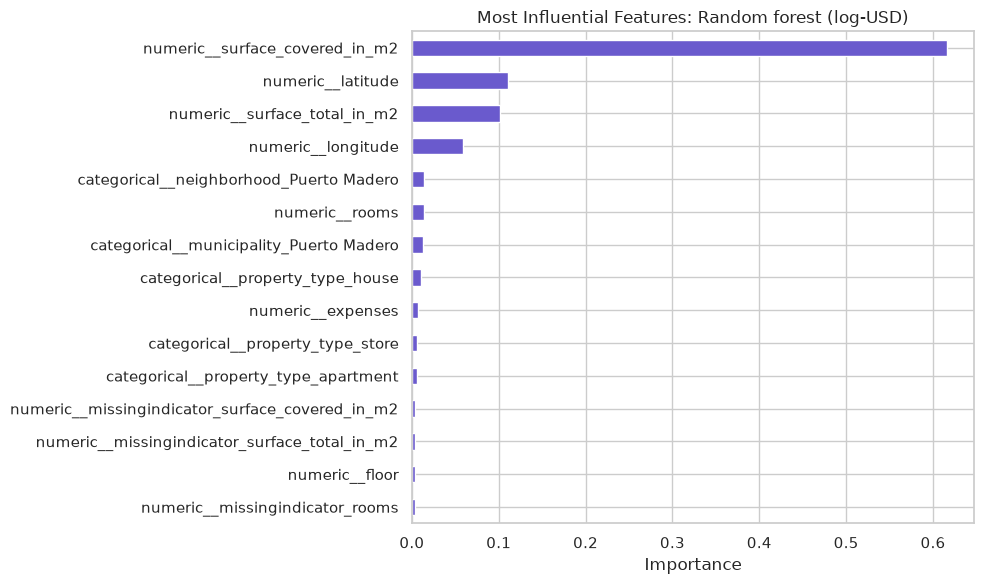

In [32]:
preprocessor_fitted = best_pipeline.named_steps["preprocessor"]
model_fitted = best_pipeline.named_steps["model"]
feature_names = preprocessor_fitted.get_feature_names_out()

if hasattr(model_fitted, "feature_importances_"):
    importance = pd.Series(model_fitted.feature_importances_, index=feature_names)
elif hasattr(model_fitted, "coef_"):
    importance = pd.Series(np.abs(model_fitted.coef_), index=feature_names)
else:
    importance = pd.Series(dtype=float)

if not importance.empty:
    top_features = importance.sort_values(ascending=False).head(15).sort_values()
    plt.figure(figsize=(10, 6))
    top_features.plot.barh(color="slateblue")
    plt.title(f"Most Influential Features: {best_key[0]} ({best_key[1]})")
    plt.xlabel("Importance")
    plt.tight_layout()
    display(top_features.sort_values(ascending=False).to_frame("importance"))

In [33]:
error_by_type = (
    residuals.groupby("property_type")
    .agg(
        listings=("actual", "size"),
        MAE=("absolute_error", "mean"),
        median_error=("error", "median"),
    )
    .sort_values("MAE", ascending=False)
)

error_by_band = residuals.groupby("price_band", observed=True).agg(
    listings=("actual", "size"),
    MAE=("absolute_error", "mean"),
    median_error=("error", "median"),
)

print("Error by property type")
display(error_by_type)
print("Error by actual-price quartile")
display(error_by_band)

Error by property type


,listings,MAE,median_error
property_type,,,
store,32,"199,000.12","21,584.49"
house,62,"128,283.13","24,624.13"
apartment,766,"39,652.69","-1,624.96"
PH,68,"37,834.81","1,874.19"


Error by actual-price quartile


,listings,MAE,median_error
price_band,,,
"(6457.129, 94462.0]",232,"18,563.47","-10,285.89"
"(94462.0, 135307.0]",232,"18,879.48",736.61
"(135307.0, 233221.165]",232,"35,419.66","4,353.80"
"(233221.165, 2600000.0]",232,"130,880.00","41,720.77"


## 12. Robustness Outside Capital Federal

Evaluate the selected Capital Federal model on other cleaned Buenos Aires listings to show where geographic generalization weakens.

In [ ]:
X_external = non_capital[feature_columns].copy()
y_external = non_capital[target].copy()
external_prediction = best_pipeline.predict(X_external)
if best_key[1] == "log-USD":
    external_prediction = np.expm1(external_prediction)
external_metrics = regression_metrics(y_external, external_prediction)
print(f"External listings: {len(X_external):,}")
print(external_metrics)

External listings: 10,558
{'MAE': 100031.60719678047, 'RMSE': np.float64(291697.5470990143), 'MAPE': np.float64(49.682921486917195), 'R2': 0.29298975829952867}


## 14. Process, Decisions, Outcome, and Readiness

### Process

1. Combined the two CSV extracts into 17,212 listings.
2. Removed exact duplicates, checked listing URLs, and kept valid sale listings with positive USD prices.
3. Parsed hierarchical locations and coordinates, corrected invalid measurements, and retained missing values for pipeline imputation.
4. Used Capital Federal as the primary market because it provides 4,638 listings across 57 neighborhoods. Other Buenos Aires listings were retained for an external robustness check.
5. Excluded `price_usd_per_m2`, `price_per_m2`, `log_price_usd`, and `properati_url` from predictors to prevent target leakage and identifier memorization.
6. Compared global and neighborhood/property-type baselines with Linear Regression, Ridge, Lasso, Random Forest, and Gradient Boosting.
7. Compared raw USD and log-USD targets using three-fold cross-validation and a fixed 80/20 test split.
8. Reviewed residuals, feature importance, property-type and price-band errors, and performance outside Capital Federal.

### Key decisions

- **Primary metric:** MAE in USD because it is directly understandable as average valuation error.
- **Supporting metrics:** RMSE exposes large errors, MAPE shows relative error, and R² measures explained variation.
- **Target comparison:** The log target was evaluated after converting predictions back to USD, so model choices were judged in business units.
- **Preprocessing:** Imputation, scaling, and one-hot encoding were fitted inside scikit-learn pipelines to avoid train-test leakage.
- **Model selection:** The current recommendation prioritizes cross-validated USD MAE, while the untouched test set remains the final reality check.

### Outcome

The project was successful as an initial, reproducible modeling study. The selected model is **Random Forest trained on log-USD prices** because it had the best cross-validated USD MAE of approximately **$58,317** and a test MAPE of **23.8%**. On the held-out Capital Federal test set, it achieved:

- **MAE:** approximately **$50,936**
- **RMSE:** approximately **$113,061**
- **MAPE:** **23.8%**
- **R²:** **0.765**

The raw-USD Random Forest produced the lowest held-out dollar error, with an MAE of approximately **$49,904**, RMSE of **$100,393**, and R² of **0.815**. This shows that target choice changes the trade-off between cross-validated relative performance and a single test split; neither result should be treated as universally superior without additional validation.

### Accuracy and known issues

The model is useful for identifying broad pricing patterns and generating approximate estimates, but it is not accurate enough to be treated as a guaranteed property valuation. An average error near $51,000 is material, especially for lower-priced properties. Error rates also vary by property type and price band, so aggregate metrics should not be used alone.

The main unresolved risks are:

- The random split may still place similar neighborhoods or listing patterns in both training and test sets.
- The data contains substantial missingness, and missing fields may reflect how listings were collected rather than property value alone.
- The target is a listing price, not a verified transaction price.
- The data represents a historical market and may not reflect current Buenos Aires prices.
- MAPE can be unstable for low-priced properties.
- Hyperparameters were benchmarked but not exhaustively tuned.
- No temporal validation, geographic holdout design, prediction intervals, drift monitoring, or human valuation review has been implemented.

### Production-readiness assessment

**Status: not production-ready.** The notebook demonstrates a valid end-to-end prototype, but production use would require stronger validation and operational controls. Before deployment, the project should add geographic and temporal holdouts, systematic hyperparameter tuning, calibrated prediction intervals, data-quality checks, model/version tracking, drift monitoring, a reproducible inference service, and regular retraining rules. External-market performance is a warning: the selected Capital Federal model achieved approximately **$100,032 MAE** and **0.293 R²** on other Buenos Aires listings, showing that geographic scope must be enforced when using predictions.

### Final conclusion

The analysis supports a **scoped decision-support model for Capital Federal**, not a universal Buenos Aires price estimator. Random Forest clearly outperformed the simple baselines and linear models in this benchmark, but the result should be communicated as an approximate estimate with documented uncertainty and market limitations.

## 13. Findings and Next Steps

The executed outputs above provide the measured model comparison and error analysis for the README. The next stage is to document the selected model, its limitations, and any deployment or monitoring requirements. No further modeling is performed in this notebook.